# Cahn–Hilliard

In [1]:
include("../src/cahn_hilliard.jl")

# true: compute that data again and save it in data/cahn_hilliard; false: load the saved data
# (steady profiles: seconds; supercritical sweep: 20 s; subcritical sweep with
# deflation: 1 minute; fold: 10 s)
COMPUTE = (profiles=false, supercritical=false, subcritical=false, fold=false)

(profiles = false, supercritical = false, subcritical = false, fold = false)

## Steady profiles: numerical continuation vs weakly nonlinear (φ0 = 0.1 and 0.5)

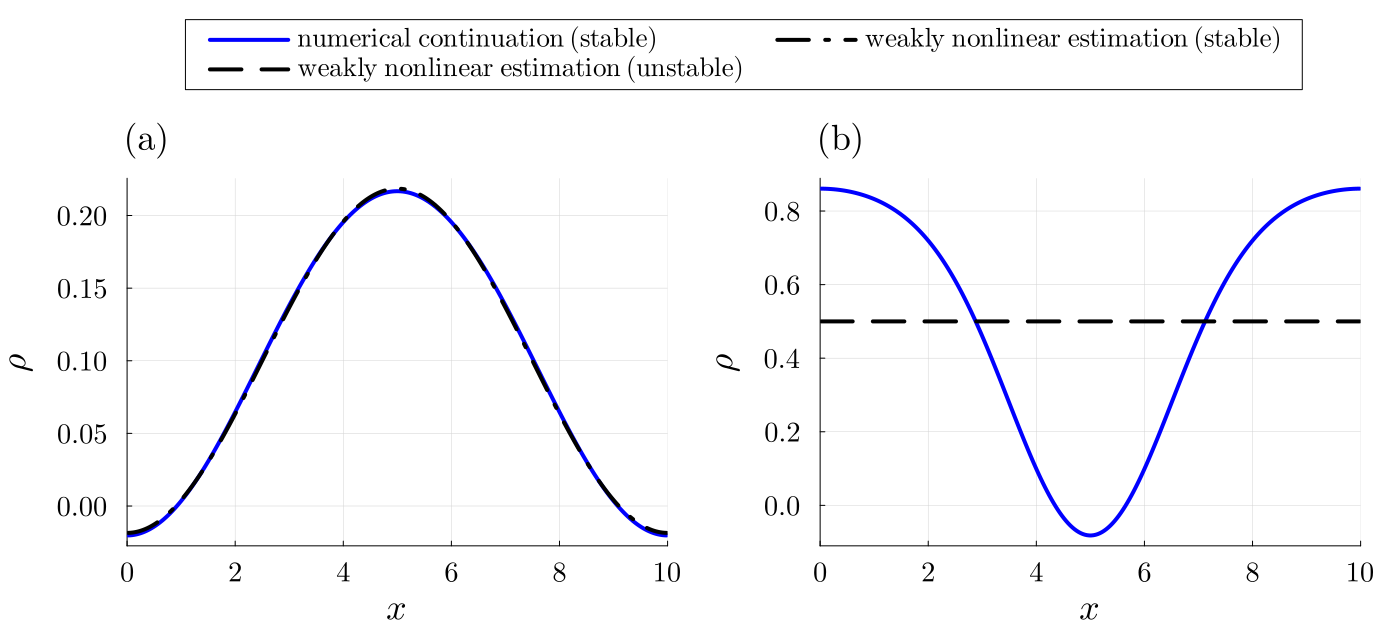

In [2]:
# Steady state of the numerical continuation (Newton) at γ = γc + δ² (δ = 0.1), against the weakly nonlinear profile
runs = [getdata(() -> steady_profile(phi0), "cahn_hilliard/steady_phi0_$(phi0).jld2", COMPUTE.profiles) for phi0 in (0.1, 0.5)]
savepdf(profiles_figure(runs), "cahn_hilliard_profiles")

## Bifurcation diagrams: supercritical (φ0 = 0.1) and subcritical (φ0 = 0.5)

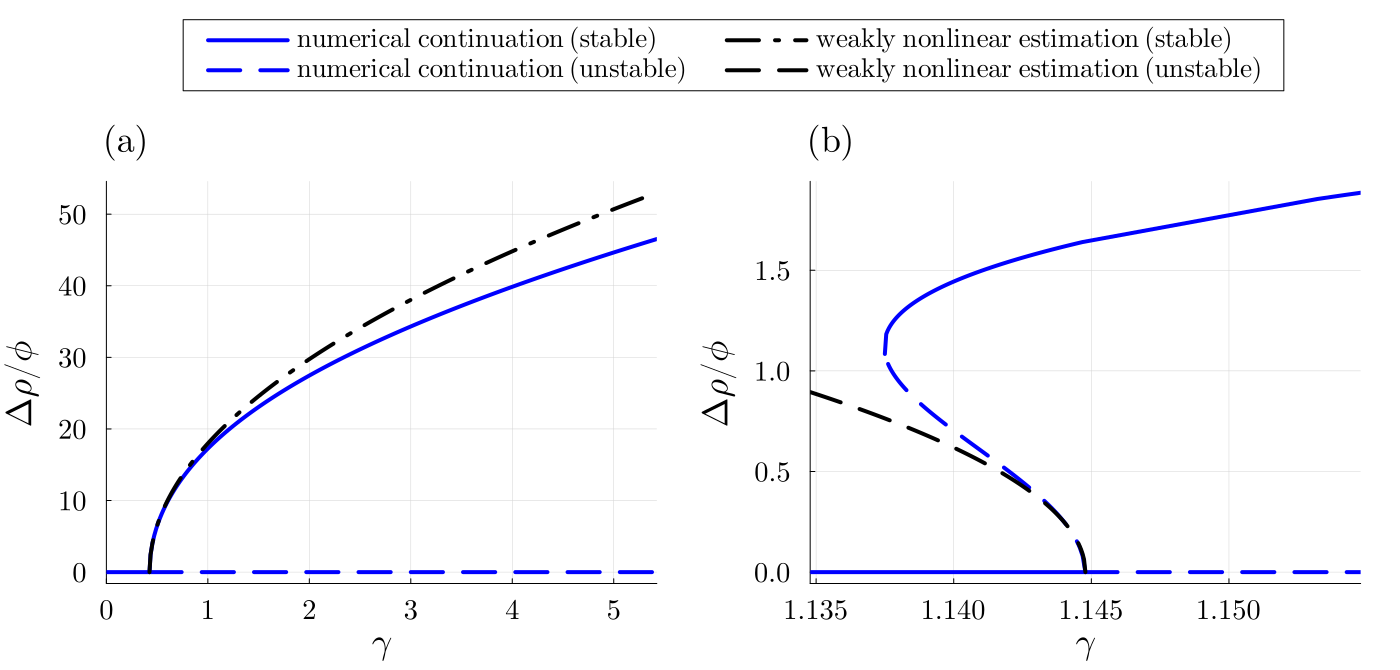

In [3]:
kC = 2π / 10
# Supercritical: Newton at 300 values of γ in [0, γc + 5]
gammaC = 3 * 0.1^2 + kC^2
sup = getdata(() -> newton_sweep(0.1, range(0.0, gammaC + 5.0, length=300)), "cahn_hilliard/supercritical_phi0_0.1.jld2",
              COMPUTE.supercritical)
# Subcritical: deflation on [γc - 0.01, γc + 0.01], 200 points below γc and 20 above
gammaC = 3 * 0.5^2 + kC^2
gammaVec = vcat(range(gammaC - 0.01, gammaC, length=200), range(gammaC, gammaC + 0.01, length=20)[2:end])
sub = getdata(() -> deflation_sweep(0.5, gammaVec), "cahn_hilliard/subcritical_phi0_0.5.jld2", COMPUTE.subcritical)
savepdf(bifurcation_figure(sup, sub), "cahn_hilliard_bifurcation")

## Fold near the tricritical point (φ0 ≈ 0.446)

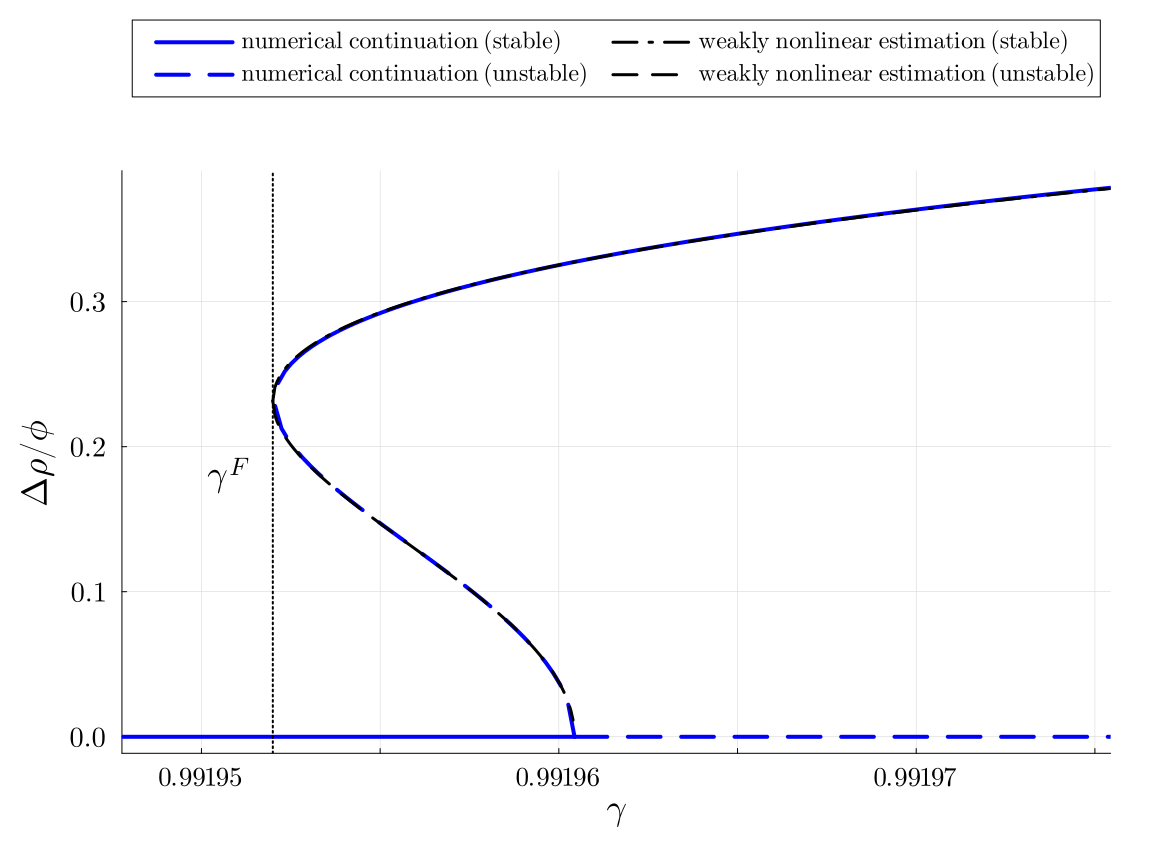

In [4]:
P = fold_setup()      # L = 10, N = 256, δ = 0.1, μ1 = 1
br = getdata(() -> fold_branch(P), "cahn_hilliard/fold_phi0_0.446.jld2", COMPUTE.fold)
savepdf(fold_figure(br, P), "cahn_hilliard_fold")